# Linear Models from Scratch and Feature Engineering

Curated from completed Artificial Intelligence coursework at Sharif University of Technology.
Repository owner: Amirhossein Hashemi Shahroodi (`amirshs84`).
Course-provided prompts, data and scaffolding are not claimed as original work; see `../../ATTRIBUTION.md`.
Run cells from top to bottom in this notebook’s directory. See the root README for scope, dependencies and limitations.


# Linear Models from Scratch and Feature Engineering

NumPy implementations of linear regression, perceptron and binary / one-vs-rest logistic regression. Synthetic datasets illustrate linear separability and polynomial feature engineering. All displayed classification accuracies here are training-set demonstrations, not held-out generalization estimates.


## Synthetic datasets

Regression, quadratic regression, one-dimensional classification, separable and overlapping blobs, circles, four-class spirals, and checkerboards. The original scikit-learn MLP/MNIST section is excluded from this curated NumPy-focused notebook.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import (
    make_regression,
    make_blobs,
    make_circles
)

# 1. Linear Regression Dataset
X_reg, y_reg = make_regression(
    n_samples=200, n_features=1, noise=15, random_state=42
)

# 2. Non-linear Regression Dataset (For Feature Engineering)
np.random.seed(42)
X_nonlin = np.sort(np.random.rand(100, 1) * 10 - 5, axis=0)
y_nonlin = 0.5 * (X_nonlin[:, 0] ** 2) + X_nonlin[:, 0] - 2 + np.random.randn(100) * 2

# 3. 1D Classification Dataset with Outlier
np.random.seed(42)
n_samples_1d = 50
X_class_1d = np.random.randn(n_samples_1d, 1) * 2
y_class_1d = (X_class_1d.flatten() > 0).astype(int)

outlier_indices = [44, 45, 46, 47]
X_class_1d[outlier_indices] = np.array([[8], [10], [9], [11]])
y_class_1d[outlier_indices] = [1, 1, 1, 1]

# 4. Linearly Separable Blobs
X_separable, y_separable = make_blobs(
    n_samples=300, n_features=2, centers=[[-4, 0], [4, 0]], cluster_std=[1, 2], random_state=42
)

# 5. Non-linearly Separable Blobs
X_nonseparable, y_nonseparable = make_blobs(
    n_samples=300, n_features=2, centers=[[-4, 0], [4, 0]], cluster_std=[2.5, 2.5], random_state=42
)

# 6. Circles
X_circles, y_circles = make_circles(
    n_samples=500, noise=0.1, factor=0.5, random_state=42
)

# 7. Spiral Dataset (4 Classes)
def generate_spiral_dataset_4classes(points_per_class=250, noise=0.2, n_classes=4):
    X = np.zeros((points_per_class * n_classes, 2))
    y = np.zeros(points_per_class * n_classes, dtype=int)
    
    for j in range(n_classes):
        ix = range(points_per_class * j, points_per_class * (j + 1))
        r = np.linspace(0.15, 1.0, points_per_class)
        
        theta_start = j * (2 * np.pi / n_classes)
        theta_end = theta_start + 4.5
        t = np.linspace(theta_start, theta_end, points_per_class)
        
        t += np.random.randn(points_per_class) * noise
        
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
        
    return X, y

X_spiral4, y_spiral4 = generate_spiral_dataset_4classes()

# 8. The Checkerboard Dataset 
def generate_checkerboard(n_samples=800, grid_size=4, noise=0.1):
    X = np.random.rand(n_samples, 2) * grid_size
    x_cell = np.floor(X[:, 0])
    y_cell = np.floor(X[:, 1])
    y = (x_cell % 2) == (y_cell % 2)
    y = y.astype(int)
    X += np.random.randn(*X.shape) * noise
    return X, y

X_checker, y_checker = generate_checkerboard(n_samples=800, grid_size=4, noise=0.1)



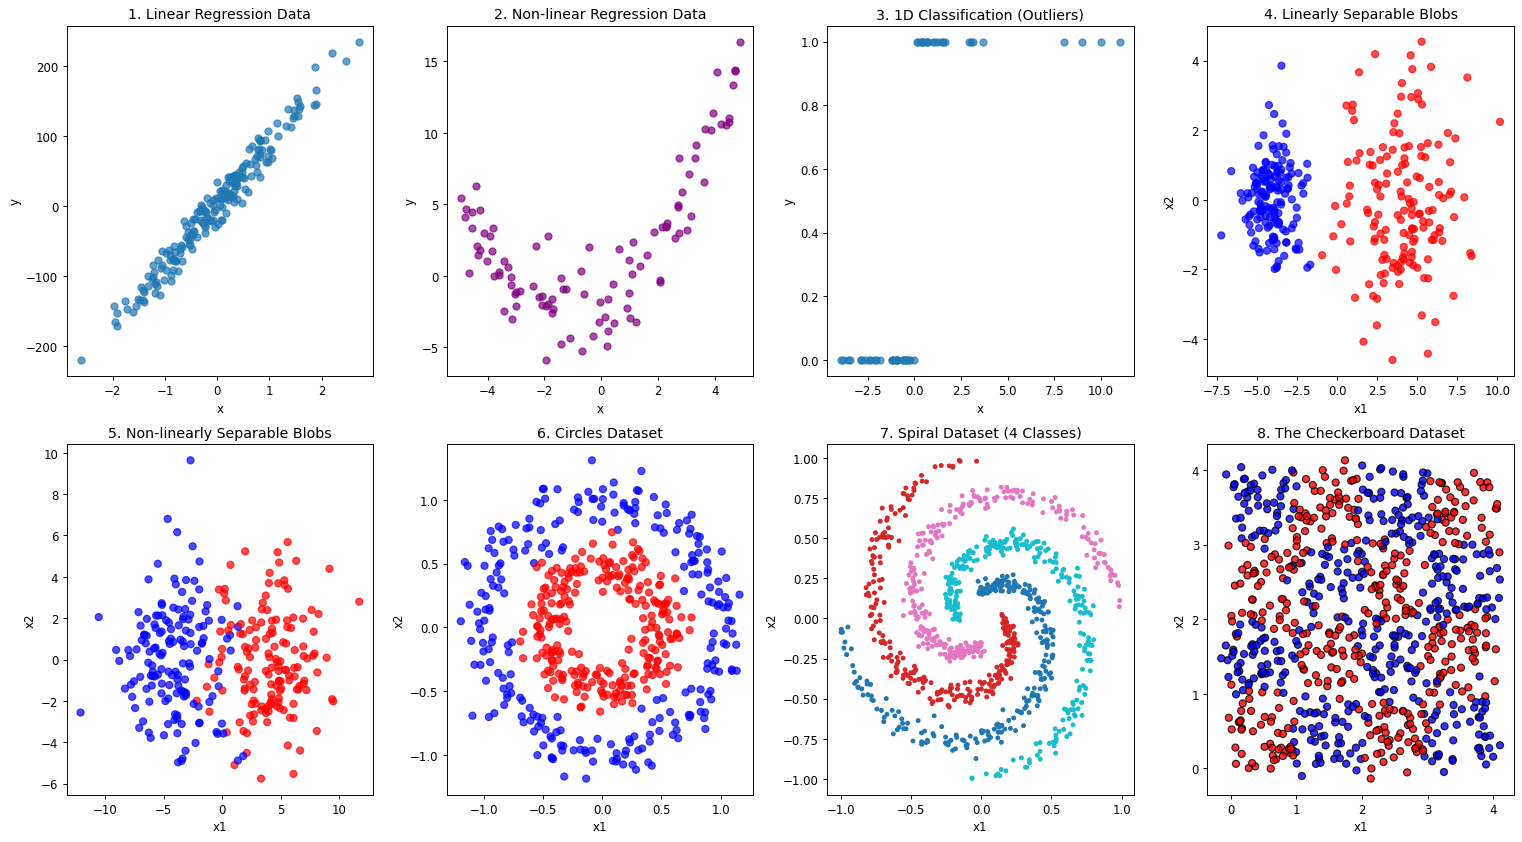

In [2]:
# Visualization of 2D Datasets (2x4 Grid)
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

# 1. Linear Regression
axes[0, 0].scatter(X_reg, y_reg, alpha=0.7)
axes[0, 0].set_title("1. Linear Regression Data")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("y")

# 2. Non-linear Regression
axes[0, 1].scatter(X_nonlin, y_nonlin, alpha=0.7, color='purple')
axes[0, 1].set_title("2. Non-linear Regression Data")
axes[0, 1].set_xlabel("x")
axes[0, 1].set_ylabel("y")

# 3. 1D Classification
axes[0, 2].scatter(X_class_1d, y_class_1d, alpha=0.7)
axes[0, 2].set_title("3. 1D Classification (Outliers)")
axes[0, 2].set_xlabel("x")
axes[0, 2].set_ylabel("y")

# 4. Separable Blobs
axes[0, 3].scatter(X_separable[:, 0], X_separable[:, 1], c=y_separable, cmap="bwr", alpha=0.7)
axes[0, 3].set_title("4. Linearly Separable Blobs")
axes[0, 3].set_xlabel("x1")
axes[0, 3].set_ylabel("x2")

# 5. Non-separable Blobs
axes[1, 0].scatter(X_nonseparable[:, 0], X_nonseparable[:, 1], c=y_nonseparable, cmap="bwr", alpha=0.7)
axes[1, 0].set_title("5. Non-linearly Separable Blobs")
axes[1, 0].set_xlabel("x1")
axes[1, 0].set_ylabel("x2")

# 6. Circles
axes[1, 1].scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles, cmap="bwr", alpha=0.7)
axes[1, 1].set_title("6. Circles Dataset")
axes[1, 1].set_xlabel("x1")
axes[1, 1].set_ylabel("x2")

# 7. Spiral (4 Classes)
axes[1, 2].scatter(X_spiral4[:, 0], X_spiral4[:, 1], c=y_spiral4, cmap="tab10", s=10)
axes[1, 2].set_title("7. Spiral Dataset (4 Classes)")
axes[1, 2].set_xlabel("x1")
axes[1, 2].set_ylabel("x2")

# 8. The Checkerboard Dataset 
axes[1, 3].scatter(X_checker[:, 0], X_checker[:, 1], c=y_checker, cmap="bwr", edgecolors="k", alpha=0.8)
axes[1, 3].set_title("8. The Checkerboard Dataset")
axes[1, 3].set_xlabel("x1")
axes[1, 3].set_ylabel("x2")

plt.tight_layout()
plt.show()



## 1. Linear Regression

Linear Regression models the relationship between inputs and a target as a linear function: $\hat{y} = \mathbf{w}^\top \mathbf{x} + b$. 

- Linear Regression
  - Linear Regression for continuous variables
  - Linear Regression for classification
  - Limitations of Linear Regression in classification tasks

### The Implementation: From Scratch with NumPy

#### Core Math

Given input $\mathbf{X} \in \mathbb{R}^{n \times p}$, weights $\mathbf{w} \in \mathbb{R}^p$, and bias $b$:

$$\hat{\mathbf{y}} = \mathbf{X}\mathbf{w} + b$$

**Loss — Mean Squared Error:**

$$J(\mathbf{w}, b) = \frac{1}{n} \|\hat{\mathbf{y}} - \mathbf{y}\|^2$$

**Gradients:**

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{2}{n} \mathbf{X}^\top (\hat{\mathbf{y}} - \mathbf{y}), \quad \frac{\partial J}{\partial b} = \frac{2}{n} \sum_i (\hat{y}_i - y_i)$$

**Gradient Descent Update (repeated for `epochs` steps):**

$$\mathbf{w} \leftarrow \mathbf{w} - \eta \frac{\partial J}{\partial \mathbf{w}}, \quad b \leftarrow b - \eta \frac{\partial J}{\partial b}$$

#### Implementation Details

Two practical enhancements make training stable across datasets with different scales:

1. **Feature Standardization:** The input is normalized to zero mean and unit variance before training. This prevents features with large magnitudes from dominating the gradient.
2. **`coef_` / `intercept_` properties:** After training in the normalized space, the learned weights and bias are mapped back to the original feature space for easy inspection.

In [3]:

import numpy as np
class LinearRegressionScratch:
    def __init__(self,learning_rate=0.1,epochs=5000,normalize=True):
        self.learning_rate=learning_rate; self.epochs=epochs; self.normalize=normalize
    def fit(self,X,y):
        X=X.astype(float); y=y.astype(float)
        if self.normalize:
            self._x_mean=X.mean(0); self._x_std=X.std(0); self._x_std[self._x_std==0]=1; X=(X-self._x_mean)/self._x_std
        self._w=np.zeros(X.shape[1]); self._b=0.
        m=len(X)
        for _ in range(self.epochs):
            p=X@self._w+self._b
            self._w-=self.learning_rate*(X.T@(p-y))/m
            self._b-=self.learning_rate*np.mean(p-y)
        return self
    @property
    def coef_(self): return self._w/self._x_std if self.normalize else self._w.copy()
    @property
    def intercept_(self): return float(self._b-np.dot(self._w/self._x_std,self._x_mean)) if self.normalize else float(self._b)
    def predict(self,X):
        if self.normalize: X=(X-self._x_mean)/self._x_std
        return X@self._w+self._b


### Simple Linear Regression
Let's start with a standard regression problem.
We will use `LinearRegressionScratch` to fit a line to our continuous dataset (`X_reg`, `y_reg`).

The model follows the familiar convention:
1. Initialize the model.
2. `fit(X, y)` — trains via gradient descent.
3. `predict(X)` — returns predictions.

Learned Coefficient (Weight): 87.1810
Learned Intercept (Bias): 2.1428


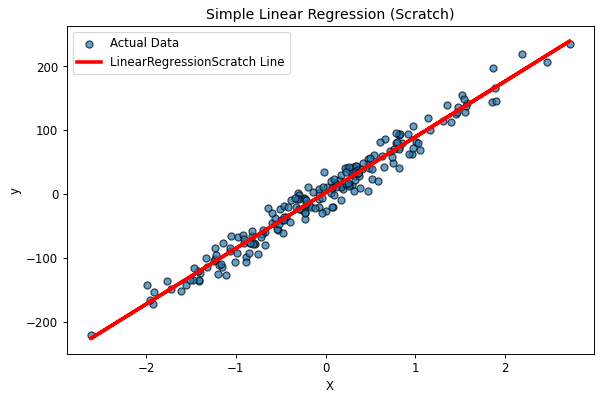

In [4]:
# Simple Linear Regression (Scratch)
lr_scratch = LinearRegressionScratch(learning_rate=0.1, epochs=5000)
lr_scratch.fit(X_reg, y_reg)
y_pred_scratch = lr_scratch.predict(X_reg)

plt.figure(figsize=(8, 5))
plt.scatter(X_reg, y_reg, alpha=0.7, edgecolors='k', label="Actual Data")
plt.plot(X_reg, y_pred_scratch, color="red", linewidth=3, label="LinearRegressionScratch Line")
plt.title("Simple Linear Regression (Scratch)")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

print(f"Learned Coefficient (Weight): {lr_scratch.coef_[0]:.4f}")
print(f"Learned Intercept (Bias): {lr_scratch.intercept_:.4f}")

### When Linear Regression Fails: Feature Engineering
What happens if the relationship between $X$ and $y$ is **not** a straight line? 
Let's generate a new non-linear dataset (a quadratic curve) and see how a simple straight line fails. 

Then, we will use **Polynomial Features** to transform our input data ($X \rightarrow X, X^2$). This allows our linear model to fit a curve!

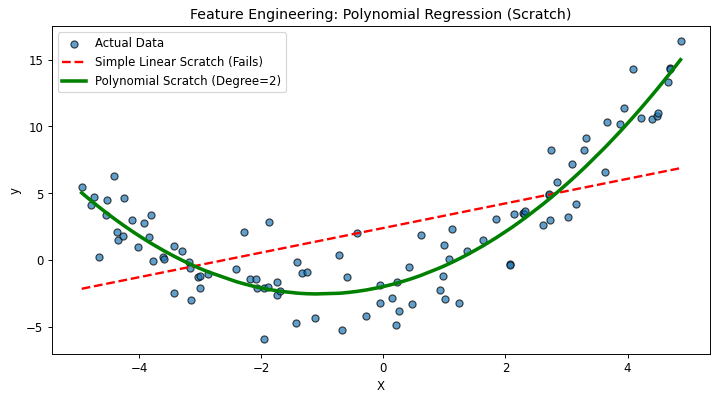

In [5]:
# Non-linear Regression with Feature Engineering (Scratch)
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_nonlin_poly = poly.fit_transform(X_nonlin)

lr_simple_scratch = LinearRegressionScratch(learning_rate=0.05, epochs=5000)
lr_simple_scratch.fit(X_nonlin, y_nonlin)
y_pred_simple_scratch = lr_simple_scratch.predict(X_nonlin)

lr_poly_scratch = LinearRegressionScratch(learning_rate=0.1, epochs=5000)
lr_poly_scratch.fit(X_nonlin_poly, y_nonlin)
y_pred_poly_scratch = lr_poly_scratch.predict(X_nonlin_poly)

plt.figure(figsize=(10, 5))
plt.scatter(X_nonlin, y_nonlin, alpha=0.7, edgecolors='k', label="Actual Data")
plt.plot(X_nonlin, y_pred_simple_scratch, color="red", linestyle="--", linewidth=2, label="Simple Linear Scratch (Fails)")
plt.plot(X_nonlin, y_pred_poly_scratch, color="green", linewidth=3, label="Polynomial Scratch (Degree=2)")
plt.title("Feature Engineering: Polynomial Regression (Scratch)")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

### Can we use Linear Regression for Classification?
Since Linear Regression works so well, can we just use it to separate classes? 
Let's try to fit a line to our `1D Classification Dataset` and use a threshold (e.g., $y = 0.5$) to say:
- If prediction $\ge 0.5 \rightarrow$ Class 1
- If prediction $< 0.5 \rightarrow$ Class 0

Watch what happens when we have **outliers** in our data.

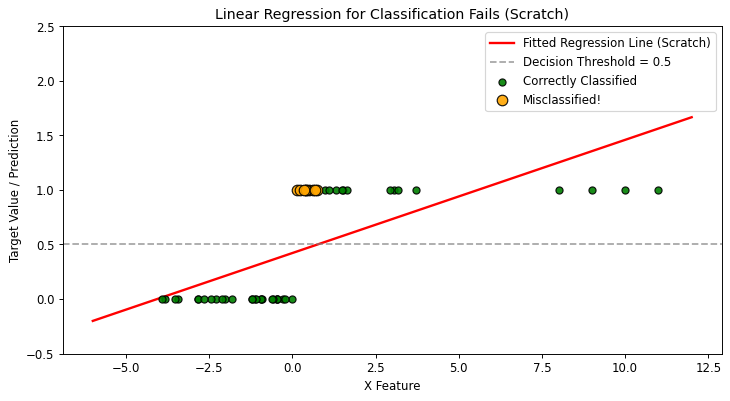

In [6]:
# Linear Regression for Classification (Scratch)
class_lr_scratch = LinearRegressionScratch(learning_rate=0.1, epochs=5000)
class_lr_scratch.fit(X_class_1d, y_class_1d)

X_plot = np.linspace(-6, 12, 300).reshape(-1, 1)
y_plot_scratch = class_lr_scratch.predict(X_plot)

y_pred_class_scratch = (class_lr_scratch.predict(X_class_1d) >= 0.5).astype(int)
correct_scratch = (y_pred_class_scratch == y_class_1d)

plt.figure(figsize=(10, 5))
plt.plot(X_plot, y_plot_scratch, color="red", linewidth=2, label="Fitted Regression Line (Scratch)")
plt.axhline(y=0.5, color="gray", linestyle="--", alpha=0.7, label="Decision Threshold = 0.5")
plt.scatter(X_class_1d[correct_scratch], y_class_1d[correct_scratch], color="green", alpha=0.9, edgecolors='k', label="Correctly Classified", zorder=5)
plt.scatter(X_class_1d[~correct_scratch], y_class_1d[~correct_scratch], color="orange", alpha=0.9, edgecolors='k', label="Misclassified!", s=80, zorder=5)
plt.xlabel("X Feature")
plt.ylabel("Target Value / Prediction")
plt.title("Linear Regression for Classification Fails (Scratch)")
plt.legend()
plt.ylim(-0.5, 2.5)
plt.show()

### Why did Linear Regression fail here?

**Your Answer:** Linear regression minimizes squared error and predicts continuous values, not class probabilities. Its linear objective does not optimize class separation, so thresholding the outputs often produces poor decision boundaries and lower classification accuracy.

## 2. Perceptron

The Perceptron is the simplest linear classifier. It computes a weighted sum and outputs 0 or 1 based on a threshold.

### How it works

For input $\mathbf{x}$, weights $\mathbf{w}$, and bias $b$:

$$\hat{y} = \begin{cases} 1 & \text{if } \mathbf{w}^\top \mathbf{x} + b \ge 0 \\ 0 & \text{otherwise} \end{cases}$$

### Learning rule

Convert labels to $\{-1, +1\}$. For each misclassified sample ($y_i \cdot (\mathbf{w}^\top \mathbf{x}_i + b) \le 0$), update:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta \, y_i \, \mathbf{x}_i, \quad b \leftarrow b + \eta \, y_i$$

> If the data is linearly separable, Perceptron converges to a perfect solution.

### The Implementation: From Scratch with NumPy

The key insight: **correctly classified points are ignored entirely** — only misclassified samples trigger a weight update. The update fires only when $y_i' \cdot (\mathbf{w}^\top \mathbf{x}_i + b) \le 0$, where $y_i' = 2y_i - 1 \in \{-1, +1\}$.

#### Implementation Details

- **Online (sample-by-sample) updates**: the dataset is shuffled each epoch and samples are visited one at a time, reflecting the Perceptron's true online learning nature rather than batch processing.
- **`coef_` has shape `(n_features,)` and `intercept_` is a scalar**, following the same convention used by the other models in this notebook.

In [7]:

import numpy as np
class PerceptronScratch:
    def __init__(self,learning_rate=1.,max_iter=1000,random_state=42):
        self.learning_rate=learning_rate; self.max_iter=max_iter; self.random_state=random_state
    def fit(self,X,y):
        y=np.where(y==0,-1,y); rng=np.random.default_rng(self.random_state)
        self.coef_=np.zeros(X.shape[1]); self.intercept_=0.
        for _ in range(self.max_iter):
            err=0
            for i in rng.permutation(len(X)):
                if y[i]*(X[i]@self.coef_+self.intercept_)<=0:
                    self.coef_+=self.learning_rate*y[i]*X[i]; self.intercept_+=self.learning_rate*y[i]; err+=1
            if err==0: break
        return self
    def predict(self,X): return ((X@self.coef_+self.intercept_)>=0).astype(int)


err 1d (scratch): 0.0
err blobs (scratch): 0.0


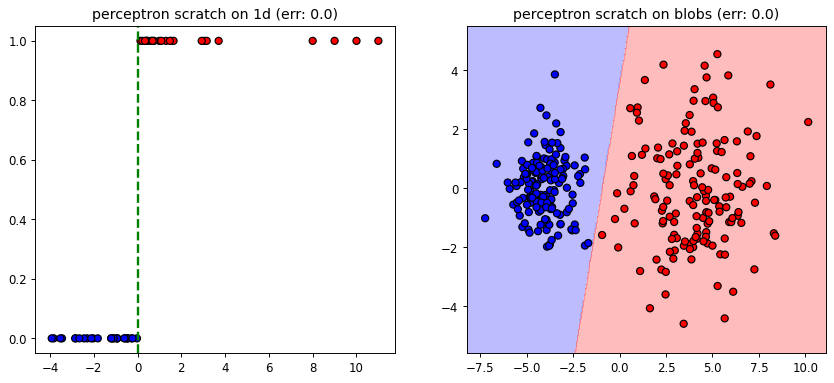

In [8]:
# Perceptron Scratch — success on separable data

p1_scratch = PerceptronScratch(learning_rate=1.0, max_iter=100)
p1_scratch.fit(X_class_1d, y_class_1d)
err1_scratch = np.mean(p1_scratch.predict(X_class_1d) != y_class_1d)
print("err 1d (scratch):", err1_scratch)

p2_scratch = PerceptronScratch(learning_rate=1.0, max_iter=1000)
p2_scratch.fit(X_separable, y_separable)
err2_scratch = np.mean(p2_scratch.predict(X_separable) != y_separable)
print("err blobs (scratch):", err2_scratch)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X_class_1d, y_class_1d, c=y_class_1d, cmap="bwr", edgecolors="k")
t_scratch = -float(np.ravel(p1_scratch.intercept_)[0]) / float(np.ravel(p1_scratch.coef_)[0])
ax[0].axvline(t_scratch, color='green', linestyle='--', linewidth=2)
ax[0].set_title("perceptron scratch on 1d (err: " + str(err1_scratch) + ")")

x_min, x_max = X_separable[:, 0].min() - 1, X_separable[:, 0].max() + 1
y_min, y_max = X_separable[:, 1].min() - 1, X_separable[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
z = p2_scratch.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax[1].contourf(xx, yy, z, alpha=0.3, cmap="bwr")
ax[1].scatter(X_separable[:, 0], X_separable[:, 1], c=y_separable, cmap="bwr", edgecolors="k")
ax[1].set_title("perceptron scratch on blobs (err: " + str(err2_scratch) + ")")

plt.show()

### The Failure of Perceptron (Non-linearly Separable Data)

The Perceptron works perfectly when a single straight line can divide the classes. But what happens if the classes overlap or form complex shapes?

If the data is **not linearly separable** (like our `X_nonseparable` blobs or circles), the Perceptron learning rule will **never converge**. The weights will keep oscillating forever as the model gets confused by the overlapping points. With a fixed number of iterations, the resulting decision boundary is arbitrary and often poor.

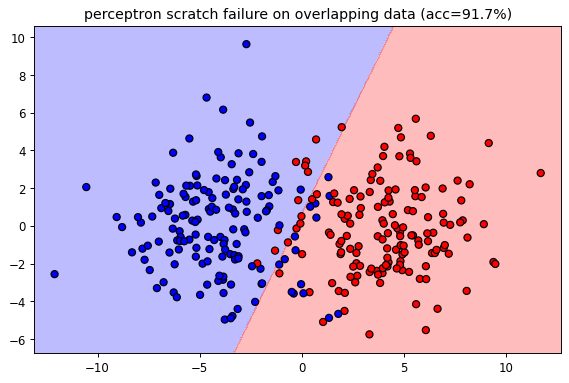

In [9]:
# Perceptron Scratch — failure on non-linearly separable data
p3_scratch = PerceptronScratch(learning_rate=1.0, max_iter=1000)
p3_scratch.fit(X_nonseparable, y_nonseparable)
err3_scratch = np.mean(p3_scratch.predict(X_nonseparable) != y_nonseparable)

x_min, x_max = X_nonseparable[:, 0].min() - 1, X_nonseparable[:, 0].max() + 1
y_min, y_max = X_nonseparable[:, 1].min() - 1, X_nonseparable[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
z = p3_scratch.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, z, alpha=0.3, cmap="bwr")
plt.scatter(X_nonseparable[:, 0], X_nonseparable[:, 1], c=y_nonseparable, cmap="bwr", edgecolors="k")
plt.title(f"perceptron scratch failure on overlapping data (acc={(1-err3_scratch)*100:.1f}%)")
plt.show()

## 3. Logistic Regression

Logistic Regression outputs **probabilities** instead of hard labels. It uses the sigmoid function to squash the linear score into $(0, 1)$.

### How it works

**Sigmoid function:**

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = \mathbf{w}^\top \mathbf{x} + b$$

**Loss function — Binary Cross-Entropy:**

$$J(\mathbf{w}, b) = -\frac{1}{n} \sum_{i=1}^{n} \bigl[ y_i \log(\hat{y}_i) + (1-y_i) \log(1-\hat{y}_i) \bigr]$$

**Gradient:**

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{n} \mathbf{X}^\top (\hat{\mathbf{y}} - \mathbf{y}), \quad \frac{\partial J}{\partial b} = \frac{1}{n} \sum (\hat{y}_i - y_i)$$

> Same form as Linear Regression, but $\hat{\mathbf{y}}$ passes through sigmoid.

### Key difference from Perceptron

| Perceptron | Logistic Regression |
|------------|---------------------|
| Hard 0/1 output | Probability $\in (0,1)$ |
| Updates only on mistakes | Updates every sample, scaled by error |
| No convergence guarantee for non-separable data | Convergence depends on optimization settings and data |

### The Implementation: From Scratch with NumPy

#### Implementation Details

- **Numerical stability**: the sigmoid clips its input to $[-500, 500]$ before calling `np.exp` to prevent overflow.
- **`predict_proba(X)`** returns per-class probabilities with shape `(n,)` for the positive class.
- **`score(X, y)`** computes accuracy so the `plot_boundary` visualization helper below works unchanged.

In [10]:

import numpy as np
class LogisticRegressionScratch:
    def __init__(self,learning_rate=0.1,max_iter=1000): self.learning_rate=learning_rate; self.max_iter=max_iter
    @staticmethod
    def _sigmoid(z): z=np.clip(z,-500,500); return 1/(1+np.exp(-z))
    def fit(self,X,y):
        self.coef_=np.zeros(X.shape[1]); self.intercept_=0.; m=len(X)
        for _ in range(self.max_iter):
            p=self._sigmoid(X@self.coef_+self.intercept_); d=p-y
            self.coef_-=self.learning_rate*(X.T@d)/m; self.intercept_-=self.learning_rate*d.mean()
        return self
    def predict_proba(self,X): return self._sigmoid(X@self.coef_+self.intercept_)
    def predict(self,X): return (self.predict_proba(X)>=0.5).astype(int)
    def score(self,X,y): return (self.predict(X)==y).mean()


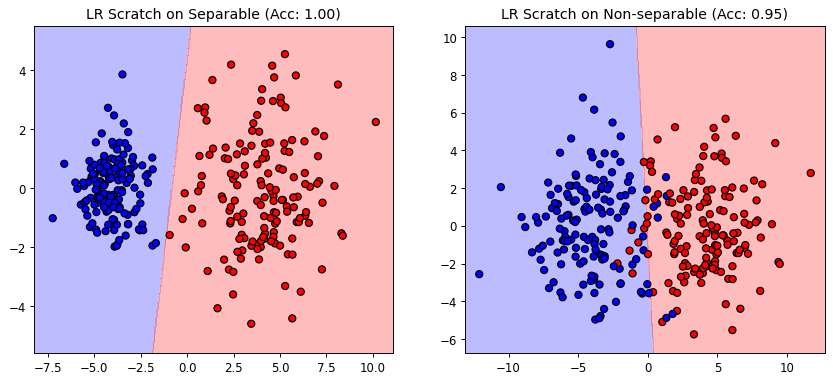

In [11]:
# Visualization helper used throughout this section
def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
    z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    z = z.reshape(xx.shape)
    ax.contourf(xx, yy, z, alpha=0.3, cmap="bwr")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    ax.set_title(title)

# Logistic Regression Scratch — Separable and Non-separable Blobs
lr_sep_scratch = LogisticRegressionScratch(learning_rate=0.5, max_iter=2000)
lr_sep_scratch.fit(X_separable, y_separable)
acc_sep_scratch = lr_sep_scratch.score(X_separable, y_separable)

lr_nonsep_scratch = LogisticRegressionScratch(learning_rate=0.5, max_iter=2000)
lr_nonsep_scratch.fit(X_nonseparable, y_nonseparable)
acc_nonsep_scratch = lr_nonsep_scratch.score(X_nonseparable, y_nonseparable)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(lr_sep_scratch, X_separable, y_separable, ax[0], f"LR Scratch on Separable (Acc: {acc_sep_scratch:.2f})")
plot_boundary(lr_nonsep_scratch, X_nonseparable, y_nonseparable, ax[1], f"LR Scratch on Non-separable (Acc: {acc_nonsep_scratch:.2f})")
plt.show()

### The Limits of Linearity: Circles, Spirals, and Checkerboards

Logistic Regression gracefully handles overlapping data by giving probabilities. However, its basic decision boundary is still just a **straight line**. 

If we apply it to a non-linear dataset like `Circles`, it will fail. We can temporarily fix this using **Feature Engineering** (e.g., adding polynomial features like $x_1^2$ and $x_2^2$ to bend the line into a circle). 

But what happens when the pattern is highly complex, like our **4-Class Spiral** or the highly repetitive **Checkerboard (Grid XOR)**? 

For these extremely non-linear datasets, manual feature engineering becomes a nightmare. We would need impractically high polynomial degrees to even attempt to separate them, which leads to massive computational costs, severe overfitting, and mathematical instability (the solver fails to converge). Let's observe how Logistic Regression completely breaks down on these tough datasets.

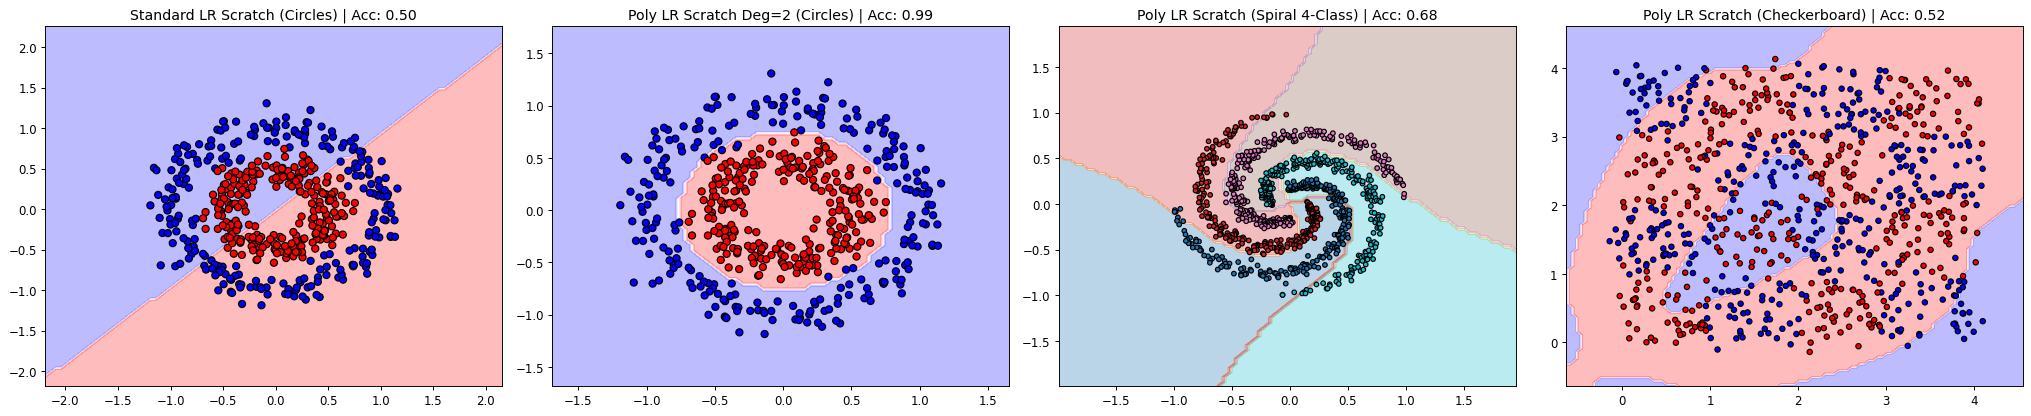

In [12]:
# Logistic Regression Scratch — Limits on Non-linear Data (all 4 datasets)
from sklearn.preprocessing import PolynomialFeatures

# One-vs-Rest wrapper to extend LogisticRegressionScratch to multi-class problems
class OvRLogisticRegressionScratch:
    def __init__(self, **kwargs):
        self.kwargs = kwargs
        self._classifiers = []
        self._classes = None

    def fit(self, X, y):
        self._classes = np.unique(y)
        self._classifiers = []
        for cls in self._classes:
            clf = LogisticRegressionScratch(**self.kwargs)
            clf.fit(X, (y==cls).astype(int))
            self._classifiers.append(clf)
        return self

    def predict(self, X):
        probs = np.column_stack([clf.predict_proba(X) for clf in self._classifiers])
        idx = np.argmax(probs, axis=1)
        return self._classes[idx]

    def score(self, X, y):
        return np.mean(self.predict(X)==y)

# 1. basic LR scratch on circles
lr_c_scratch = LogisticRegressionScratch(learning_rate=0.5, max_iter=2000)
lr_c_scratch.fit(X_circles, y_circles)
acc_c_scratch = lr_c_scratch.score(X_circles, y_circles)

# 2. LR scratch with poly on circles
poly_tf_c = PolynomialFeatures(degree=2)
X_circles_poly = poly_tf_c.fit_transform(X_circles)
lr_pc_scratch = LogisticRegressionScratch(learning_rate=0.1, max_iter=5000)
lr_pc_scratch.fit(X_circles_poly, y_circles)
acc_pc_scratch = lr_pc_scratch.score(X_circles_poly, y_circles)

# 3. OvR LR scratch with poly on 4-class spiral
poly_tf_s = PolynomialFeatures(degree=4)
X_spiral_poly = poly_tf_s.fit_transform(X_spiral4)
lr_sp_scratch = OvRLogisticRegressionScratch(learning_rate=0.1, max_iter=5000)
lr_sp_scratch.fit(X_spiral_poly, y_spiral4)
acc_sp_scratch = lr_sp_scratch.score(X_spiral_poly, y_spiral4)

# 4. LR scratch with poly on checkerboard
poly_tf_chk = PolynomialFeatures(degree=8)
X_checker_poly = poly_tf_chk.fit_transform(X_checker)
lr_chk_scratch = LogisticRegressionScratch(learning_rate=0.01, max_iter=5000)
lr_chk_scratch.fit(X_checker_poly, y_checker)
acc_chk_scratch = lr_chk_scratch.score(X_checker_poly, y_checker)

# plots
fig, ax = plt.subplots(1, 4, figsize=(24, 5))

plot_boundary(lr_c_scratch, X_circles, y_circles, ax[0], f"Standard LR Scratch (Circles) | Acc: {acc_c_scratch:.2f}")

# poly circles — mesh needs polynomial features too
x_min, x_max = X_circles[:, 0].min() - 0.5, X_circles[:, 0].max() + 0.5
y_min, y_max = X_circles[:, 1].min() - 0.5, X_circles[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
z_pc = lr_pc_scratch.predict(poly_tf_c.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
ax[1].contourf(xx, yy, z_pc, alpha=0.3, cmap="bwr")
ax[1].scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles, cmap="bwr", edgecolors="k")
ax[1].set_title(f"Poly LR Scratch Deg=2 (Circles) | Acc: {acc_pc_scratch:.2f}")

# poly spiral (4-class)
x_min_s, x_max_s = X_spiral4[:, 0].min() - 1, X_spiral4[:, 0].max() + 1
y_min_s, y_max_s = X_spiral4[:, 1].min() - 1, X_spiral4[:, 1].max() + 1
xx_s, yy_s = np.meshgrid(np.arange(x_min_s, x_max_s, 0.05), np.arange(y_min_s, y_max_s, 0.05))
z_s = lr_sp_scratch.predict(poly_tf_s.transform(np.c_[xx_s.ravel(), yy_s.ravel()])).reshape(xx_s.shape)
ax[2].contourf(xx_s, yy_s, z_s, alpha=0.3, cmap="tab10")
ax[2].scatter(X_spiral4[:, 0], X_spiral4[:, 1], c=y_spiral4, cmap="tab10", edgecolors="k", s=15)
ax[2].set_title(f"Poly LR Scratch (Spiral 4-Class) | Acc: {acc_sp_scratch:.2f}")

# poly checkerboard
x_min_c, x_max_c = X_checker[:, 0].min() - 0.5, X_checker[:, 0].max() + 0.5
y_min_c, y_max_c = X_checker[:, 1].min() - 0.5, X_checker[:, 1].max() + 0.5
xx_c, yy_c = np.meshgrid(np.arange(x_min_c, x_max_c, 0.05), np.arange(y_min_c, y_max_c, 0.05))
z_c = lr_chk_scratch.predict(poly_tf_chk.transform(np.c_[xx_c.ravel(), yy_c.ravel()])).reshape(xx_c.shape)
ax[3].contourf(xx_c, yy_c, z_c, alpha=0.3, cmap="bwr")
ax[3].scatter(X_checker[:, 0], X_checker[:, 1], c=y_checker, cmap="bwr", edgecolors="k", s=20)
ax[3].set_title(f"Poly LR Scratch (Checkerboard) | Acc: {acc_chk_scratch:.2f}")

plt.tight_layout()
plt.show()